# Phishing website detection with interpretable baselines

**Research question.** How well can a Logistic Regression baseline and a Random Forest distinguish phishing from legitimate websites using the engineered indicators in the Kaggle Phishing Website Dataset, and what do false negatives and false positives mean for a security team?

This is an independent, reproducible classroom analysis. It uses the Kaggle dataset `akashkr/phishing-website-dataset` (11,055 rows; 30 predictors, plus a row index and target in the CSV). The Kaggle file mirrors the UCI Phishing Websites benchmark. It contains engineered categorical indicators, not live URLs or page content. The target is `Result`: `-1` phishing, `1` legitimate; the notebook converts phishing to the positive class. No network requests are sent to websites.

**Scope:** offline classification for learning, not an operational blocking product. Both models use the same stratified, grouped held-out test split; no test data is used to fit preprocessing or tune thresholds.


## 1. Run this notebook

**Online:** [Open in Google Colab](https://colab.research.google.com/github/you01ssef/Assignment-1/blob/main/analysis/phishing_analysis.ipynb), connect to a Python runtime, and choose **Runtime → Run all**. The setup cell installs only missing packages. The loader uses a local CSV when available, otherwise downloads version 2 of the public Kaggle dataset. No Kaggle notebook or solution code is downloaded.

**Locally:** use Python 3.11 or newer. From the repository folder:

```sh
python -m venv .venv
source .venv/bin/activate
# Windows PowerShell: .venv\Scripts\Activate.ps1
python -m pip install -r requirements-analysis.txt
jupyter lab analysis/phishing_analysis.ipynb
```

Use **Restart Kernel and Run All Cells** to reproduce the analysis. The pinned requirements reproduce the saved environment; Colab may already have different compatible library versions, which are printed below. Small numerical differences can occur across versions.

The first run needs internet access to obtain missing packages and the dataset. For an offline run, install the requirements beforehand and place the Kaggle `dataset.csv` in `data/`. A standalone copy of this notebook also works: outputs are saved in a `reports/` folder beside its working directory. On Kaggle, outputs go to `/kaggle/working/reports/`.


In [1]:
# Install missing packages before importing the analysis libraries.
import importlib.util
import subprocess
import sys

required = {
    "numpy": "numpy==2.2.6",
    "pandas": "pandas==2.2.3",
    "matplotlib": "matplotlib==3.10.3",
    "seaborn": "seaborn==0.13.2",
    "sklearn": "scikit-learn==1.7.2",
    "kagglehub": "kagglehub==0.4.3",
}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
print("Setup ready. Run the remaining cells in order.")


Setup ready. Run the remaining cells in order.


In [2]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import json
import platform
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

SEED = 42
sns.set_theme(style="whitegrid", palette="crest")
pd.set_option("display.max_columns", 35)

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents]
             if (p / "requirements-analysis.txt").is_file()
             and (p / "analysis").is_dir()), None)
if ROOT is None:
    ROOT = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else cwd
OUT = ROOT / "reports" / "figures"
OUT.mkdir(parents=True, exist_ok=True)
versions = {name: version(name) for name in required.values()
            for name in [name.split("==")[0]]}
print("Python:", platform.python_version())
display(pd.Series(versions, name="installed_version").to_frame())
print("Results will be saved under reports/.")


Python: 3.11.5


,installed_version
numpy,2.2.6
pandas,2.2.3
matplotlib,3.10.3
seaborn,0.13.2
scikit-learn,1.7.2
kagglehub,0.4.3


Results will be saved under reports/.


## 2. Dataset selection

| Requirement | Selected dataset |
|---|---|
| Name | **Phishing website dataset**, published on Kaggle by Akash Kumar |
| Kaggle URL | https://www.kaggle.com/datasets/akashkr/phishing-website-dataset |
| Version used | 2 (`dataset.csv`) |
| Description | Historical website observations represented by URL, domain, certificate, page-link, and traffic indicators; a Kaggle mirror of the UCI Phishing Websites benchmark. |
| Records | 11,055 |
| Predictor features | 30; the CSV has 32 columns including `index` and `Result`. |
| Target | `Result`: −1 = phishing, +1 = legitimate. We map phishing to 1 for evaluation. |

The CSV contains engineered indicators, **not raw URLs**. It is suitable for studying classification and security errors, but cannot be used to scan a new URL directly. This project implements its own analysis using the cited libraries rather than reproducing someone else's Kaggle notebook.

### Important features

| Column in the Kaggle CSV | Meaning |
|---|---|
| `having_IPhaving_IP_Address` | Whether the URL uses an IP address instead of a domain name. |
| `URLURL_Length` | URL length category. |
| `Shortining_Service` | Use of a URL shortening service. |
| `SSLfinal_State` | HTTPS and certificate state indicator. |
| `URL_of_Anchor` | Behavior and destinations of links on the page. |
| `Request_URL` | External-domain page resources. |
| `age_of_domain` | Domain age category. |
| `web_traffic` | Website traffic or ranking category. |

Feature values are encoded categories, usually −1, 0, or 1; they are not probabilities or raw measurements. Source column spellings are preserved. See the [complete feature dictionary](https://github.com/you01ssef/Assignment-1/blob/main/reports/feature_dictionary.md).


In [3]:
# Optional: set this to your downloaded dataset.csv; otherwise leave it as None.
DATA_FILE = None
DATASET_HANDLE = "akashkr/phishing-website-dataset/versions/2"
EXPECTED_SHA256 = "83853a3ddf39a77e4bda0c8c907c5a7f521f16ed844299de75d215c22d5bd379"

if DATA_FILE is not None:
    DATA_PATH = Path(DATA_FILE).expanduser().resolve()
    if not DATA_PATH.is_file():
        raise FileNotFoundError("DATA_FILE must point to an existing dataset.csv file.")
else:
    candidates = [ROOT / "data" / "dataset.csv", ROOT / "dataset.csv", cwd / "dataset.csv"]
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.is_dir():
        candidates += [p for p in kaggle_input.rglob("dataset.csv")
                       if "phishing-website-dataset" in p.parts]
    DATA_PATH = next((p for p in candidates if p.is_file()), None)
    if DATA_PATH is None:
        import kagglehub
        try:
            download_dir = Path(kagglehub.dataset_download(DATASET_HANDLE))
            matches = sorted(download_dir.rglob("dataset.csv"))
            if len(matches) != 1:
                raise FileNotFoundError("Expected one dataset.csv in the Kaggle archive.")
            DATA_PATH = matches[0]
        except Exception as exc:
            raise RuntimeError(
                "Could not download the Kaggle dataset. Check internet access, or download "
                "version 2 from https://www.kaggle.com/datasets/akashkr/phishing-website-dataset "
                "and set DATA_FILE above to the extracted dataset.csv. "
                "If Kaggle asks for consent, complete that on Kaggle first."
            ) from exc

data_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
if data_sha256 != EXPECTED_SHA256:
    warnings.warn("This CSV differs from the saved version-2 file; compare results with care.")
df = pd.read_csv(DATA_PATH)
if df.columns.duplicated().any():
    raise ValueError("Duplicate column names found. Use the original Kaggle CSV.")
target_col = "Result"
if target_col not in df.columns or df[target_col].isna().any():
    raise ValueError("The CSV needs a non-missing Result target column.")
if set(df[target_col].unique()) != {-1, 1}:
    raise ValueError("Expected Result labels -1 (phishing) and 1 (legitimate).")
feature_cols = [c for c in df.columns if c not in {target_col, "index"}]
if len(feature_cols) != 30 or not all(pd.api.types.is_numeric_dtype(df[c]) for c in feature_cols):
    raise ValueError("Expected the Kaggle benchmark's 30 numeric predictor columns.")
if any(df[c].isna().all() for c in feature_cols):
    raise ValueError("A predictor is entirely missing; check the source file.")
if not np.isfinite(df[feature_cols].to_numpy(dtype=float)[~df[feature_cols].isna().to_numpy()]).all():
    raise ValueError("Infinite predictor values found; check the source file.")
print(f"Loaded {DATA_PATH.name}: {df.shape[0]:,} records × {df.shape[1]} columns")
print("SHA-256:", data_sha256)
display(df.head())


Loaded dataset.csv: 11,055 records × 32 columns
SHA-256: 83853a3ddf39a77e4bda0c8c907c5a7f521f16ed844299de75d215c22d5bd379


,index,having_IPhaving_IP_Address,URLURL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,port,HTTPS_token,Request_URL,URL_of_Anchor,Links_in_tags,SFH,Submitting_to_email,Abnormal_URL,Redirect,on_mouseover,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,1,-1,1,1,1,-1,-1,-1,-1,-1,1,1,-1,1,-1,1,-1,-1,-1,0,1,1,1,1,-1,-1,-1,-1,1,1,-1,-1
1,2,1,1,1,1,1,-1,0,1,-1,1,1,-1,1,0,-1,-1,1,1,0,1,1,1,1,-1,-1,0,-1,1,1,1,-1
2,3,1,0,1,1,1,-1,-1,-1,-1,1,1,-1,1,0,-1,-1,-1,-1,0,1,1,1,1,1,-1,1,-1,1,0,-1,-1
3,4,1,0,1,1,1,-1,-1,-1,1,1,1,-1,-1,0,0,-1,1,1,0,1,1,1,1,-1,-1,1,-1,1,-1,1,-1
4,5,1,0,-1,1,1,-1,1,1,-1,1,1,1,1,0,0,-1,1,1,0,-1,1,-1,1,-1,-1,0,-1,1,1,1,1


## 3. Data quality and class distribution

The Kaggle CSV contains a sequential `index` column in addition to 30 predictors and `Result`. The index is metadata and is removed before modeling. Missing-value handling stays inside each model pipeline so any imputation statistics are learned from training data only. Duplicate rows are checked before splitting.


,value,meaning
records,11055,records
columns,32,CSV columns
missing_cells,0,missing cells
exact_duplicate_rows,0,exact duplicate CSV rows
repeated_profiles,5206,repeated predictor/label profiles (index removed)
conflicting_profiles,64,profiles with conflicting labels
unique_index_values,11055,unique row-index values


Target values: {-1: 4898, 1: 6157}
Target share: {-1: 0.4431, 1: 0.5569}
Predictor columns: 30  | dtypes: {dtype('int64'): 30}
Unique-value counts (predictors):


,number_of_features
unique_values_per_feature,
2,22
3,8


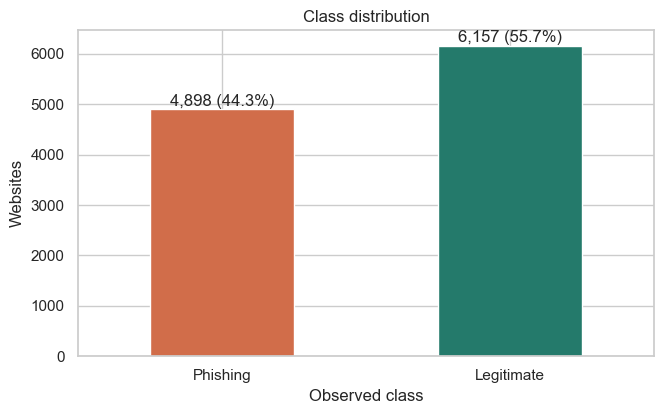

In [4]:
without_index = df.drop(columns=["index"], errors="ignore")
feature_label_duplicates = int(without_index.duplicated().sum())
conflicting_profiles = int(without_index.groupby(feature_cols, dropna=False)[target_col].nunique().gt(1).sum())
quality = pd.DataFrame({
    "value": [len(df), df.shape[1], int(df.isna().sum().sum()), int(df.duplicated().sum()),
              feature_label_duplicates, conflicting_profiles,
              int(df["index"].nunique()) if "index" in df.columns else np.nan],
    "meaning": ["records", "CSV columns", "missing cells", "exact duplicate CSV rows",
                "repeated predictor/label profiles (index removed)", "profiles with conflicting labels",
                "unique row-index values"]
}, index=["records", "columns", "missing_cells", "exact_duplicate_rows", "repeated_profiles", "conflicting_profiles", "unique_index_values"])
display(quality)
print("Target values:", df[target_col].value_counts(dropna=False).sort_index().to_dict())
print("Target share:", df[target_col].value_counts(normalize=True).sort_index().round(4).to_dict())
feature_preview = df.drop(columns=[target_col, "index"], errors="ignore")
print("Predictor columns:", feature_preview.shape[1], " | dtypes:", feature_preview.dtypes.value_counts().to_dict())
print("Unique-value counts (predictors):")
display(feature_preview.nunique().value_counts().sort_index().rename_axis("unique_values_per_feature").to_frame("number_of_features"))

fig, ax = plt.subplots(figsize=(6.8, 4.3))
counts = df[target_col].map({-1: "Phishing", 1: "Legitimate"}).value_counts().reindex(["Phishing", "Legitimate"])
counts.plot.bar(ax=ax, color=["#d16d4a", "#247a6b"])
ax.set(title="Class distribution", xlabel="Observed class", ylabel="Websites")
ax.tick_params(axis="x", rotation=0)
for i, value in enumerate(counts): ax.text(i, value + 70, f"{value:,} ({value/len(df):.1%})", ha="center")
fig.tight_layout(); fig.savefig(OUT / "class_distribution.png", dpi=180); plt.show()


## 4. Feature distributions and association

Features are integer-coded indicators (usually −1, 0, 1), not continuous measurements. The plots show representative URL, domain, and page indicators. Correlations describe this dataset's engineered features and should not be read as causal effects.


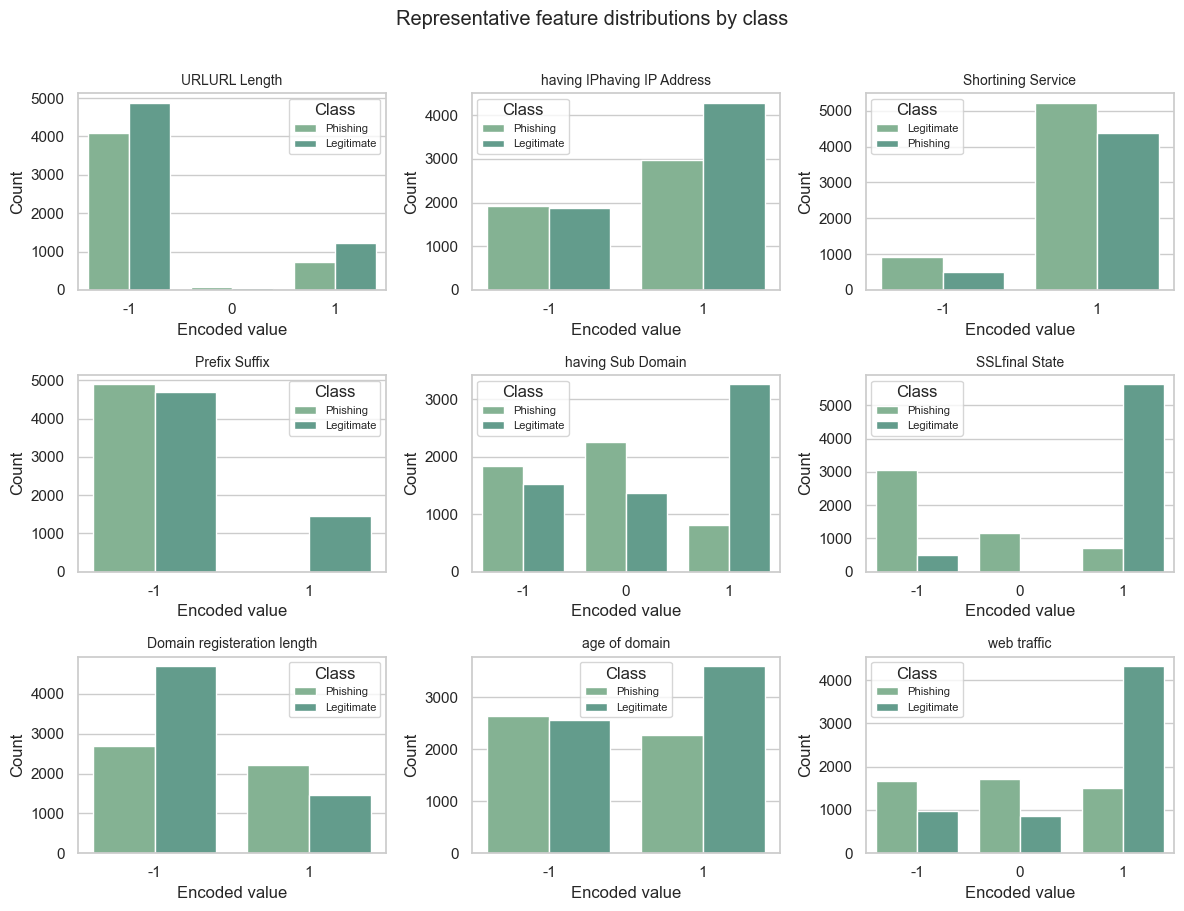

Largest absolute feature/target correlations:


,pearson_r
SSLfinal_State,0.714741
URL_of_Anchor,0.692935
Prefix_Suffix,0.348606
web_traffic,0.346103
having_Sub_Domain,0.298323
Request_URL,0.253372
Links_in_tags,0.248229
Domain_registeration_length,-0.225789
SFH,0.221419
Google_Index,0.128950


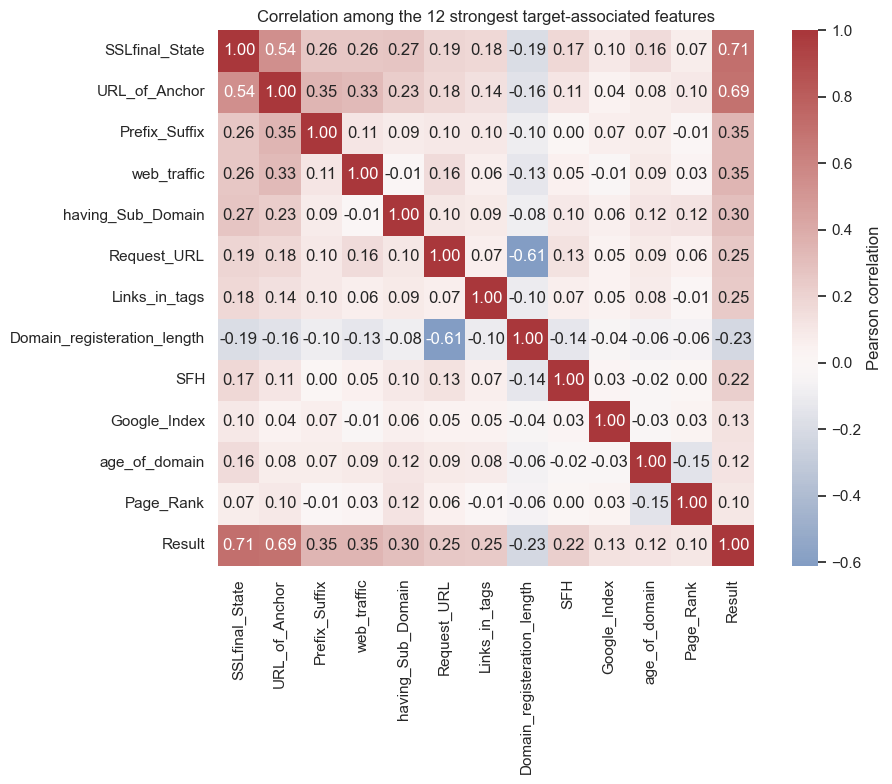

EDA interpretation:
• The sample is moderately imbalanced; report phishing recall and false alarms alongside accuracy.
• These are coarse indicator categories, not continuous URL measurements.
• Certificate state and anchor behavior show strong target association in this historical sample.
• Correlations are descriptive; all 30 predictors are retained, so the test set is not used for feature selection.


In [5]:
label = df[target_col].map({-1: "Phishing", 1: "Legitimate"})
selected = [c for c in ["URLURL_Length", "having_IPhaving_IP_Address", "Shortining_Service",
                        "Prefix_Suffix", "having_Sub_Domain", "SSLfinal_State",
                        "Domain_registeration_length", "age_of_domain", "web_traffic"] if c in feature_cols]
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, col in zip(axes.flat, selected):
    sns.countplot(data=pd.DataFrame({"value": df[col], "class": label}), x="value", hue="class", ax=ax)
    ax.set_title(col.replace("_", " "), fontsize=10); ax.set_xlabel("Encoded value"); ax.set_ylabel("Count")
    ax.legend(title="Class", fontsize=8)
for ax in axes.flat[len(selected):]: ax.set_visible(False)
fig.suptitle("Representative feature distributions by class", y=1.01)
fig.tight_layout(); fig.savefig(OUT / "feature_distributions.png", dpi=180, bbox_inches="tight"); plt.show()

correlations = df[feature_cols + [target_col]].corr(numeric_only=True)
target_corr = correlations[target_col].drop(target_col).sort_values(key=np.abs, ascending=False)
print("Largest absolute feature/target correlations:")
display(target_corr.head(10).rename("pearson_r").to_frame())
heat_features = target_corr.head(12).index.tolist() + [target_col]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlations.loc[heat_features, heat_features], cmap="vlag", center=0, annot=True,
            fmt=".2f", square=True, ax=ax, cbar_kws={"label": "Pearson correlation"})
ax.set_title("Correlation among the 12 strongest target-associated features")
fig.tight_layout(); fig.savefig(OUT / "correlation_heatmap.png", dpi=180); plt.show()
print("EDA interpretation:")
print("• The sample is moderately imbalanced; report phishing recall and false alarms alongside accuracy.")
print("• These are coarse indicator categories, not continuous URL measurements.")
print("• Certificate state and anchor behavior show strong target association in this historical sample.")
print("• Correlations are descriptive; all 30 predictors are retained, so the test set is not used for feature selection.")


## 5. Preprocessing and model plan

1. Drop the sequential row index because it does not describe website risk.
2. Check exact duplicate CSV rows before removing the index. The quality table above reports both exact duplicates and repeated predictor profiles. Some predictor profiles have both target labels. Those can represent distinct websites with the same coarse engineered indicators; they are not safe to delete as duplicate records.
3. Map the dataset's `-1` phishing label to positive class `1`; legitimate becomes `0`.
4. Use a stratified, grouped 80/20 split with seed 42. Grouping by the full predictor signature prevents identical feature profiles from crossing train/test; stratification keeps the phishing share close across folds.
5. Impute numeric missing values with the training-set median inside each pipeline. The source benchmark has no missing cells, but the pipeline makes the workflow robust to them.
6. Standardize features for Logistic Regression because its regularization is scale-sensitive. Random Forest does not need scaling. We retain the source indicator scores as a simple baseline. This assumes ordered, equally spaced effects in Logistic Regression; merely being numeric does not prove a categorical feature should be treated as continuous. One-hot encoding is a reasonable future comparison. Class weighting reduces the training objective's preference for the larger legitimate class without synthesizing examples.

Logistic Regression is an interpretable linear baseline. Random Forest captures feature interactions and nonlinear splits. The final test set is held out for one comparison; this notebook does not tune on it.


In [6]:
X = df[feature_cols].copy()
y = df[target_col].map({-1: 1, 1: 0}).astype(int)  # positive = phishing
assert set(y.unique()) == {0, 1}, "Unexpected target coding; verify source labels before continuing."
groups = pd.util.hash_pandas_object(X, index=False).astype(str)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx])), "A feature profile crossed the split."
print(f"Train: {len(X_train):,}; test: {len(X_test):,}; phishing train share: {y_train.mean():.3f}; test share: {y_test.mean():.3f}")
print(f"Exact duplicates in source: {df.duplicated().sum()}; repeated profiles retained: {feature_label_duplicates:,}; conflicting-label profiles: {conflicting_profiles}.")

numeric_features = X.columns.tolist()
linear_prep = ColumnTransformer([("numeric", Pipeline([
    ("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())
]), numeric_features)], remainder="drop")
tree_prep = ColumnTransformer([("numeric", SimpleImputer(strategy="median"), numeric_features)], remainder="drop")
models = {
    "Logistic Regression": Pipeline([("prep", linear_prep),
        ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED))]),
    "Random Forest": Pipeline([("prep", tree_prep),
        ("model", RandomForestClassifier(n_estimators=400, min_samples_leaf=2,
            class_weight="balanced_subsample", n_jobs=2, random_state=SEED))])
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Fitted {name}.")
print("Models fitted on the training split.")
split_summary = pd.DataFrame({
    "records": [len(X_train), len(X_test)],
    "phishing": [int(y_train.sum()), int(y_test.sum())],
    "legitimate": [int((y_train == 0).sum()), int((y_test == 0).sum())],
    "unique_profiles": [groups.iloc[train_idx].nunique(), groups.iloc[test_idx].nunique()]
}, index=["Train", "Test"])
display(split_summary)
print("Shared predictor profiles between train and test: 0 (asserted above)")


Train: 8,859; test: 2,196; phishing train share: 0.441; test share: 0.452
Exact duplicates in source: 0; repeated profiles retained: 5,206; conflicting-label profiles: 64.
Fitted Logistic Regression.


Fitted Random Forest.
Models fitted on the training split.


,records,phishing,legitimate,unique_profiles
Train,8859,3905,4954,4621
Test,2196,993,1203,1164


Shared predictor profiles between train and test: 0 (asserted above)


## 6. Held-out evaluation

The positive class is phishing. A false negative is a phishing website labeled legitimate, which can expose users to credential or payment theft. A false positive is a legitimate website flagged for review or blocked, which creates friction and can disrupt access. Accuracy alone hides these asymmetric operational costs, so precision, recall, F1, ROC-AUC, FPR, FNR, and confusion counts are reported.


,accuracy,precision_phishing,recall_phishing,f1_phishing,roc_auc,false_positive_rate,false_negative_rate,tn,fp,fn,tp
model,,,,,,,,,,,
Logistic Regression,0.922,0.900,0.930,0.915,0.974,0.085,0.070,"1,101",102,70,923
Random Forest,0.944,0.939,0.937,0.938,0.986,0.050,0.063,"1,143",60,63,930


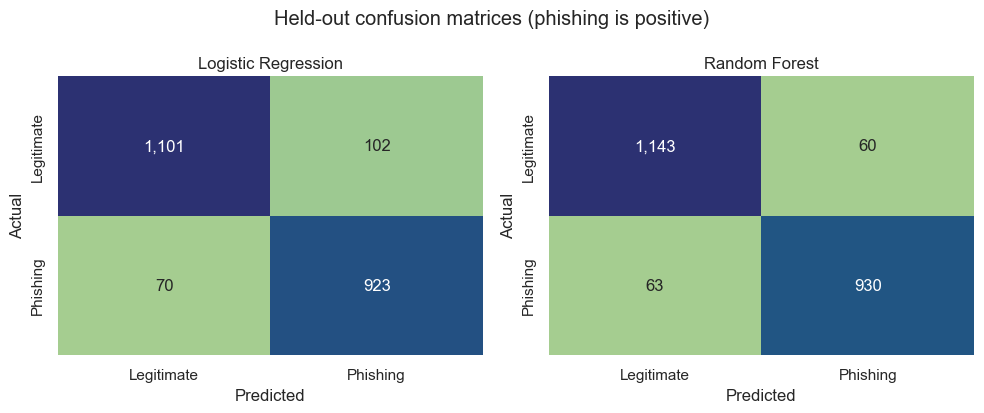

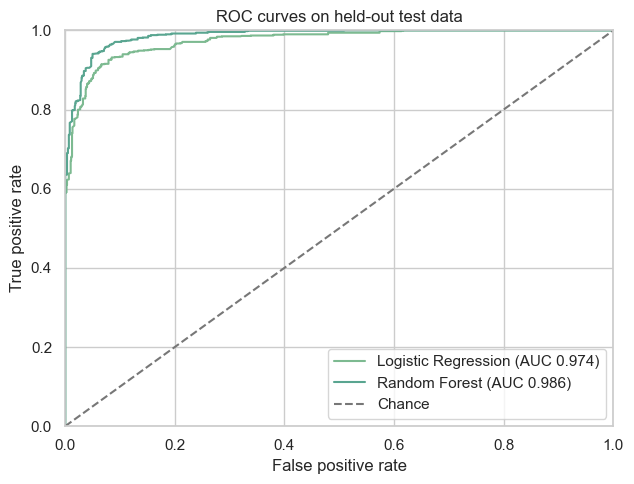

In [7]:
results = []
predictions = {}
for name, model in models.items():
    pred = model.predict(X_test)
    score = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    results.append({"model": name, "accuracy": accuracy_score(y_test, pred),
        "precision_phishing": precision_score(y_test, pred, zero_division=0),
        "recall_phishing": recall_score(y_test, pred, zero_division=0),
        "f1_phishing": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, score),
        "false_positive_rate": fp / (fp + tn), "false_negative_rate": fn / (fn + tp),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)})
    predictions[name] = (pred, score)
metrics = pd.DataFrame(results).set_index("model")
display(metrics.style.format({**{c: "{:.3f}" for c in metrics.columns},
                             **{c: "{:,.0f}" for c in ["tn", "fp", "fn", "tp"]}}))
metrics.to_csv(ROOT / "reports" / "model_metrics.csv")
with open(ROOT / "reports" / "model_metrics.json", "w") as f: json.dump(metrics.reset_index().to_dict(orient="records"), f, indent=2)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (name, (pred, score)) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0,1])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="crest", cbar=False, ax=ax,
                xticklabels=["Legitimate", "Phishing"], yticklabels=["Legitimate", "Phishing"])
    ax.set(title=name, xlabel="Predicted", ylabel="Actual")
fig.suptitle("Held-out confusion matrices (phishing is positive)")
fig.tight_layout(); fig.savefig(OUT / "confusion_matrices.png", dpi=180, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5))
for name, (pred, score) in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, score)
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, score):.3f})")
ax.plot([0,1],[0,1], linestyle="--", color="#777", label="Chance")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves on held-out test data", xlim=(0,1), ylim=(0,1))
ax.legend(loc="lower right"); fig.tight_layout(); fig.savefig(OUT / "roc_curves.png", dpi=180); plt.show()


## 7. Feature importance

Permutation importance measures the decrease in held-out ROC-AUC when a feature is shuffled. Correlated indicators can substitute for one another, so importance is predictive association—not causal proof or an explanation of a particular site's behavior. The data has no live URL, time, source organization, or attack campaign fields, so these results cannot identify which real attacks are hardest to detect.


,feature,mean_auc_drop,std_auc_drop
7,SSLfinal_State,0.0691,0.0046
13,URL_of_Anchor,0.0610,0.0031
25,web_traffic,0.0132,0.0011
5,Prefix_Suffix,0.0116,0.0012
14,Links_in_tags,0.0062,0.0011
6,having_Sub_Domain,0.0053,0.0004
15,SFH,0.0034,0.0011
28,Links_pointing_to_page,0.0026,0.0003
27,Google_Index,0.0023,0.0003
12,Request_URL,0.0020,0.0004


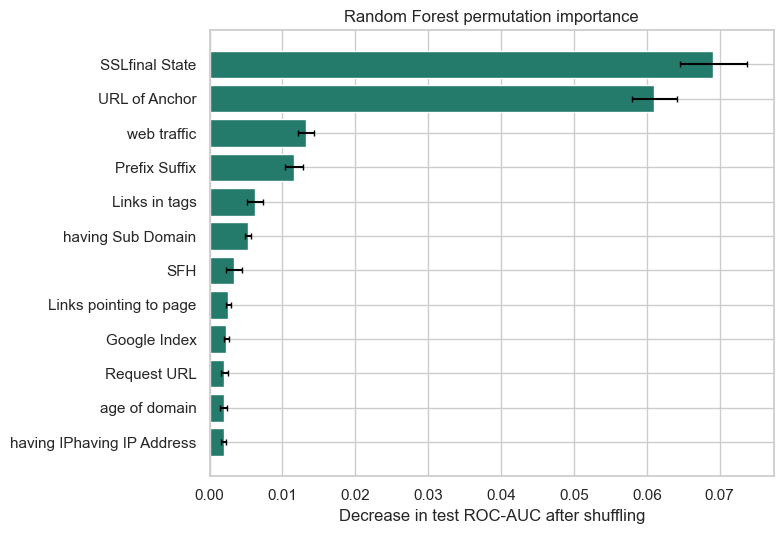

In [8]:
rf = models["Random Forest"]
perm = permutation_importance(rf, X_test, y_test, scoring="roc_auc", n_repeats=10,
                              random_state=SEED, n_jobs=1)
importance = pd.DataFrame({"feature": X.columns, "mean_auc_drop": perm.importances_mean,
                           "std_auc_drop": perm.importances_std}).sort_values("mean_auc_drop", ascending=False)
display(importance.head(12).style.format({"mean_auc_drop":"{:.4f}","std_auc_drop":"{:.4f}"}))
importance.to_csv(ROOT / "reports" / "permutation_importance.csv", index=False)
top = importance.head(12).sort_values("mean_auc_drop")
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.feature.str.replace("_", " "), top.mean_auc_drop, xerr=top.std_auc_drop, color="#247a6b", capsize=2)
ax.set(xlabel="Decrease in test ROC-AUC after shuffling", title="Random Forest permutation importance")
fig.tight_layout(); fig.savefig(OUT / "permutation_importance.png", dpi=180, bbox_inches="tight"); plt.show()


## 8. Results and security interpretation

The following summary is calculated from this run's results. A **false negative** is a phishing record missed by the model; a **false positive** is a legitimate record flagged as phishing. Neither metric alone establishes that a model is safe to deploy.


In [9]:
rf_metrics = metrics.loc["Random Forest"]
lr_metrics = metrics.loc["Logistic Regression"]
top_features = ", ".join(f"`{name}`" for name in importance.head(3).feature)
display(Markdown(
    f"**Random Forest** achieved **{rf_metrics.accuracy:.1%} accuracy**, "
    f"**{rf_metrics.recall_phishing:.1%} phishing recall**, and **{rf_metrics.roc_auc:.3f} ROC-AUC**. "
    f"It missed **{int(rf_metrics.fn)} of {int(y_test.sum()):,} phishing records** and "
    f"flagged **{int(rf_metrics.fp)} of {int((y_test == 0).sum()):,} legitimate records**.\n\n"
    f"Logistic Regression achieved {lr_metrics.accuracy:.1%} accuracy and missed "
    f"{int(lr_metrics.fn)} phishing records, with {int(lr_metrics.fp)} false alarms. "
    f"The strongest measured Random Forest signals were {top_features}.\n\n"
    "Missed phishing can expose users to credential theft. False alarms create review work "
    "and can interrupt legitimate browsing. These results support an offline analyst-triage "
    "experiment, not automatic blocking or a claim that an unflagged live website is safe."
))

manifest = {
    "dataset": DATASET_HANDLE, "dataset_sha256": data_sha256,
    "records": int(len(df)), "predictors": len(feature_cols),
    "seed": SEED, "split": "first fold of StratifiedGroupKFold(n_splits=5, shuffle=True)",
    "train_records": len(X_train), "test_records": len(X_test),
    "shared_profiles": 0, "positive_class": "phishing",
    "python": platform.python_version(), "packages": versions,
}
(ROOT / "reports" / "run_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
print("Saved metrics, permutation importance, six figures, and run_manifest.json to reports/.")


**Random Forest** achieved **94.4% accuracy**, **93.7% phishing recall**, and **0.986 ROC-AUC**. It missed **63 of 993 phishing records** and flagged **60 of 1,203 legitimate records**.

Logistic Regression achieved 92.2% accuracy and missed 70 phishing records, with 102 false alarms. The strongest measured Random Forest signals were `SSLfinal_State`, `URL_of_Anchor`, `web_traffic`.

Missed phishing can expose users to credential theft. False alarms create review work and can interrupt legitimate browsing. These results support an offline analyst-triage experiment, not automatic blocking or a claim that an unflagged live website is safe.

Saved metrics, permutation importance, six figures, and run_manifest.json to reports/.


## 9. Limitations and next steps

The benchmark is a static, engineered-feature dataset collected from historical sources. It omits raw pages, deployment context, temporal drift, provenance groups, and modern attacker adaptation. Identical predictor profiles stay together in this split, but related campaigns or similar profiles may still occur on both sides; results may overstate generalization to new attacks. Several indicators encode heuristic judgments and may be stale. No threshold was calibrated to an operational review budget. Class weighting is a baseline response to moderate imbalance; it does not make the sample representative.

The experiment provides a reproducible comparison of one linear and one tree ensemble model. Interpret it as a controlled benchmark, not a guarantee about real-world phishing defense. A stronger deployment study would use time-based and source-separated testing, current threat feeds, calibration, subgroup/error review, drift monitoring, and analyst-in-the-loop decisions.


## 10. References

- Akash Kumar. *Phishing website dataset* (Kaggle), dataset mirror: <https://www.kaggle.com/datasets/akashkr/phishing-website-dataset>.
- Rami Mohammad, Fadi Thabtah, and Lee McCluskey. “An assessment of features related to phishing websites using an automated technique.” *International Conference for Internet Technology and Secured Transactions*, 2012. Dataset record: <https://archive.ics.uci.edu/dataset/327/phishing+websites> (DOI: 10.24432/C51W2X; CC BY 4.0).
- Scikit-learn documentation: <https://scikit-learn.org/stable/>; pandas: <https://pandas.pydata.org/>; seaborn: <https://seaborn.pydata.org/>.

This is a project-specific implementation rather than a reproduction of a Kaggle notebook. Libraries are cited as tools; the preprocessing, model comparison, evaluation, visualizations, and security interpretation in this notebook are original for this project.
- KaggleHub dataset downloader: <https://github.com/Kaggle/kagglehub>.
